# HW 2/1

In [1]:
import numpy as np

strike = 100
step_size = 0.001

x_stock_price = np.arange(0, 2 * strike, step_size)
y_forward_payoff = np.array([x - strike for x in x_stock_price])

y_forward_payoff__short = y_forward_payoff * (-1)
y_forward_payoff__short

array([100.   ,  99.999,  99.998, ..., -99.997, -99.998, -99.999],
      shape=(200000,))

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams # detailed parameter setting
""" more details on customization: https://matplotlib.org/stable/tutorials/introductory/customizing.html """
from typing import Dict, List, Union


# some type hints in the header of the function
def my_plotter(x: List[float], y: Union[List[float], List[List[float]]], layout: Dict = {}, names: List[str] = None, colors = None , linestyles = None) -> None:
    """ inline for loop is called 'list comprehension' """
    y = [y] if all(isinstance(item, float) for item in y) else y
    
#     plt.figure(figsize=(8, 4))
    plt.figure(figsize=layout.get('figsize', (8, 4))) #replaced prev line
    lines = []
    show_legend = True if names is not None else False
    # show_legend = True if names else False  -> here is fine, but be cautious bc 0, empty str and empty list will be evaulated to False

    """ setup some basic key-word arguments for plot line """
    plot_kwargs = {
#         'linestyle': 'solid',
#         'linewidth': 4
        'linestyle': layout.get('linestyle', 'solid'), #added
        'linewidth': layout.get('linewidth', 4) #added
    }
    if names is not None:
        show_legend = True
        if len(names) != len(y):
            raise ValueError("Length of names is not matching with number of plotted y lists.")

    """ 'enumerate' add a counter to the loop """
    for i, y_item in enumerate(y):
        if show_legend:
            plot_kwargs['label'] = names[i]
        if colors is not None:
            plot_kwargs['color'] = colors[i] #added
        if linestyles is not None:
            plot_kwargs['linestyle'] = linestyles[i]

        _line = plt.plot(x, y_item, **plot_kwargs)
        lines.append(_line)

    if show_legend:
#         plt.legend(fontsize=16)
        plt.legend(fontsize=layout.get('legend_fontsize', 16),loc=layout.get('legend_loc', 'best'))

    if 'title' in layout:
#         plt.title(layout['title'], fontsize=20)
#         rcParams['axes.titlepad'] = 30 # moving the title a little further away from the plot
        plt.title(layout['title'], fontsize=layout.get('title_fontsize', 20))
        rcParams['axes.titlepad'] = layout.get('titlepad', 30)
    if 'x_label' in layout:
#         plt.xlabel(layout['x_label'], fontsize=16)
#         rcParams['axes.labelpad'] = 20 # moving the ax label a little further away from the plot
        plt.xlabel(layout['x_label'], fontsize=layout.get('label_fontsize', 16))
        rcParams['axes.labelpad'] = layout.get('labelpad', 20)
    if 'y_label' in layout:
#         plt.ylabel(layout['y_label'], fontsize=16)
        plt.ylabel(layout['y_label'], fontsize=layout.get('label_fontsize', 16))
   

    """ enhance axes """
    ax = plt.gca() # gca: get current axes
    ax.axhline(linestyle='--', color='black', linewidth=1)
    plt.show()

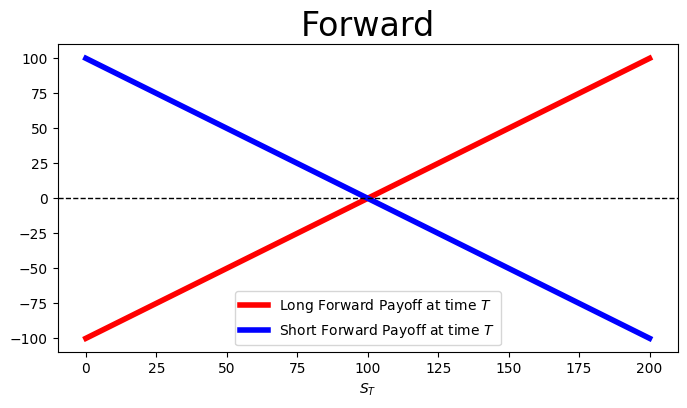

In [3]:
layout = {
    'title': 'Forward',
    'x_label': '$S_{T}$',
    'y_label': None,
    'title_fontsize': 24,    
    'label_fontsize': 10 ,
    'legend_fontsize':10,
    'legend_loc': None #'upper right'
}
names=['Long Forward Payoff at time $T$', 'Short Forward Payoff at time $T$']
my_plotter(x_stock_price, [y_forward_payoff, y_forward_payoff__short], layout=layout, names = names, colors = ['red','b'])

# HW2/2

In [4]:
from scipy.special import erf
from scipy.stats import norm


In [5]:
def black_scholes_eur_call(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray], return_greeks: bool = False):
    """
    Black-Scholes pricer of European call option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    param return_greeks: if True, return a dict with price and greeks
    """
    assert sigma > 0

    K = np.array([K]) if isinstance(K, float) else np.array(K)

    d1_vec = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * T**0.5)
    d2_vec = d1_vec - sigma * T**0.5

    N_d1_vec = norm.cdf(d1_vec) #cdf
    N_d2_vec = norm.cdf(d2_vec)#cdf
    
    price = N_d1_vec * S0 - K * np.exp(-r * T) * N_d2_vec

    if not return_greeks:
        return price
    n_d1_vec = norm.pdf(d1_vec)  #pdf
    delta = N_d1_vec
    gamma = n_d1_vec / (S0 * sigma * T**0.5)
    vega = S0 * n_d1_vec * T**0.5
    theta = -(S0 * n_d1_vec * sigma) / (2 * T**0.5) - r * K * np.exp(-r * T) * N_d2_vec
    rho = K * T * np.exp(-r * T) * N_d2_vec

    return {
        'price': price,
        'delta': delta,
        'gamma': gamma,
        'vega': vega,
        'theta': theta,
        'rho': rho
    }

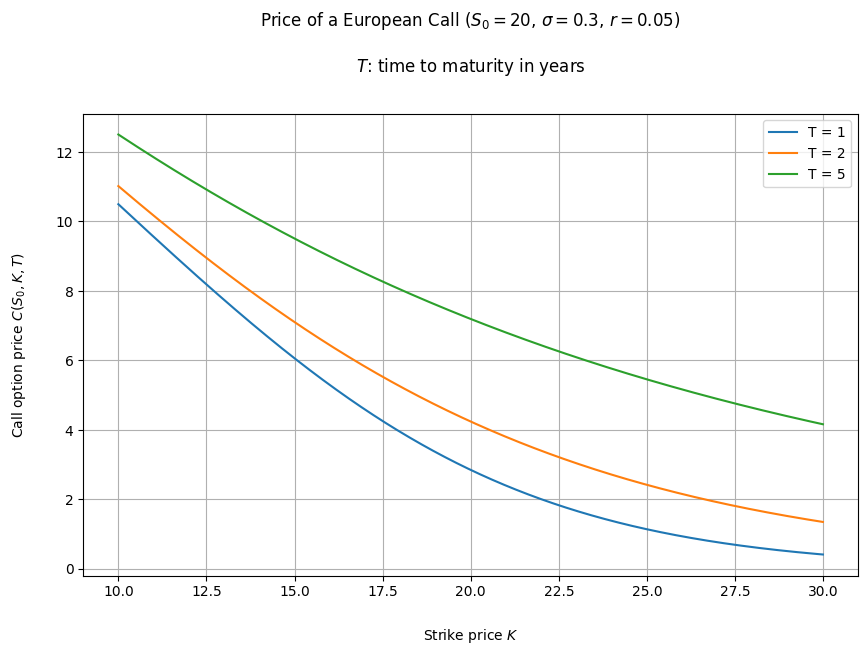

In [6]:
#see if normal version still works
# Strike prices for which the option price is calculated
K_vec = np.arange(10, 30, 0.01)

# Time to maturities (in year fractions)
T_vec = [1.0, 2.0, 5.0]

prices_to_plot = []
for _T in T_vec:
    prices_to_plot.append(black_scholes_eur_call(r=0.05, T=_T, S0=20.0, sigma=0.3, K=K_vec))

plt.figure(figsize=(10, 6))

for prices, T in zip(prices_to_plot, T_vec):
    plt.plot(K_vec, prices, label=f"T = {int(T)}")

plt.title(
    'Price of a European Call ($S_0 = 20$, $\\sigma = 0.3$, $r = 0.05$)\n\n'
    '$T$: time to maturity in years'
)

plt.xlabel('Strike price $K$')
plt.ylabel('Call option price $C(S_0,K,T)$')

plt.legend()
plt.grid(True)
plt.show()

In [7]:
#now with greeks
result = black_scholes_eur_call(r=0.05, T=1.0, S0=20.0, sigma=0.3, K=20.0, return_greeks=True)

for key, value in result.items():
    print(f"{key}: {value}")

price: [2.84625096]
delta: [0.62425173]
gamma: [0.06323882]
vega: [7.58865866]
theta: [-1.62023798]
rho: [9.6387836]


# HW 2/3

In [8]:
def black_scholes_eur_put(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray], return_greeks: bool = False):
    """
    Black-Scholes pricer of European call option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    param return_greeks: if True, return a dict with price and greeks
    """
    assert sigma > 0

    K = np.array([K]) if isinstance(K, float) else np.array(K)

    d1_vec = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * T**0.5)
    d2_vec = d1_vec - sigma * T**0.5

    N_d1_vec = norm.cdf(d1_vec) #cdf
    N_d2_vec = norm.cdf(d2_vec)#cdf
    
#     price = N_d1_vec * S0 - K * np.exp(-r * T) * N_d2_vec
    price = K * np.exp(-r * T) * norm.cdf(-d2_vec) - S0 * norm.cdf(-d1_vec)
    return price

In [9]:
black_scholes_eur_put(r=0.05, T=1.0, S0=20.0, sigma=0.3, K=20.0, return_greeks=True)


array([1.87083945])

# HW 2/4
so we need to check if C-P = S_0 - PV(K) holds


In [10]:
# varying K
K_vec = np.arange(10, 30, 0.01)
r, T, S0, sigma = 0.05, 1.0, 20.0, 0.3

call_price = black_scholes_eur_call(r=r, T=T, S0=S0, sigma=sigma, K=K_vec)
put_price = black_scholes_eur_put(r=r, T=T, S0=S0, sigma=sigma, K=K_vec)

# Left side vs right side
LHS = call_price - put_price
RHS = S0 - K_vec * np.exp(-r * T)


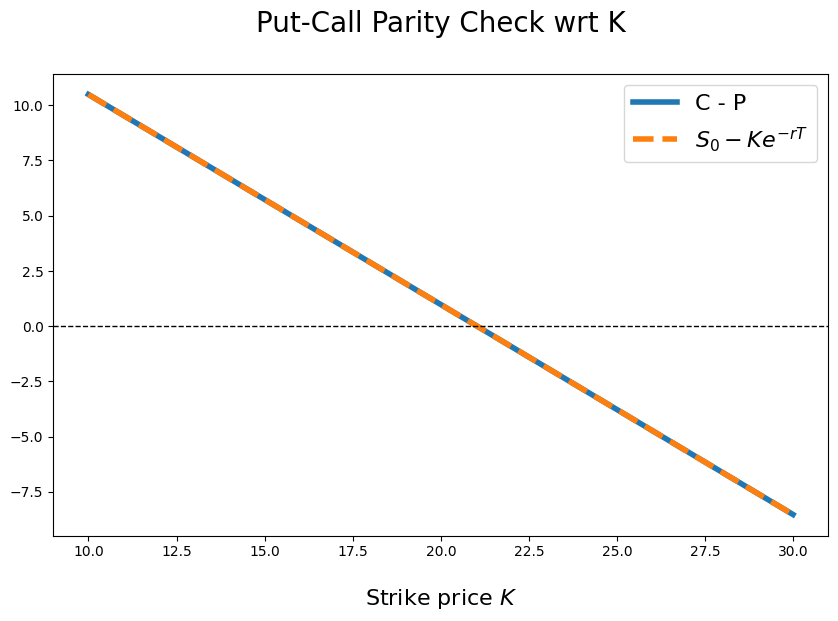

In [11]:

layout = {
    'title': 'Put-Call Parity Check wrt K',
    'x_label': 'Strike price $K$',
    'figsize': (10, 6)
}

my_plotter(K_vec, [LHS, RHS], layout=layout, names=['C - P', '$S_0 - Ke^{-rT}$'], colors=None , linestyles = ['solid', 'dashed'])

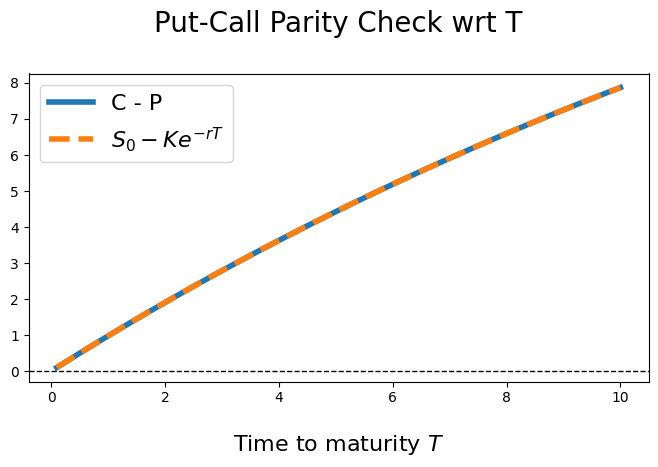

In [12]:
#vary T 
T_vec = np.linspace(0.1, 10, 1000)
r, S0, sigma, K = 0.05, 20.0, 0.3, 20.0

LHS = [black_scholes_eur_call(r=r, T=t, S0=S0, sigma=sigma, K=K)[0] - 
        black_scholes_eur_put(r=r, T=t, S0=S0, sigma=sigma, K=K)[0] for t in T_vec]
RHS = [S0 - K * np.exp(-r * t) for t in T_vec]

layout = {
    'title': 'Put-Call Parity Check wrt T',
    'x_label': 'Time to maturity $T$',
}

my_plotter(T_vec, [LHS, RHS], 
           layout=layout, 
           names=['C - P', '$S_0 - Ke^{-rT}$'], 
           colors=None, 
           linestyles=['solid', 'dashed']
          )